# Order Delivery Time Prediction

## Objectives
The objective of this project is to build a regression model that predicts the delivery time for orders placed through Porter. The model will use various features such as the items ordered, the restaurant location, the order protocol, and the availability of delivery partners.

The key goals are:
- Predict the delivery time for an order based on multiple input features
- Improve delivery time predictions to optimiae operational efficiency
- Understand the key factors influencing delivery time to enhance the model's accuracy

## Data Pipeline
The data pipeline for this assignment will involve the following steps:
1. **Data Loading**
2. **Data Preprocessing and Feature Engineering**
3. **Exploratory Data Analysis**
4. **Model Building**
5. **Model Inference**

## Data Understanding
The dataset contains information on orders placed through Porter, with the following columns:

| Field                     | Description                                                                                 |
|---------------------------|---------------------------------------------------------------------------------------------|
| market_id                 | Integer ID representing the market where the restaurant is located.                         |
| created_at                | Timestamp when the order was placed.                                                        |
| actual_delivery_time      | Timestamp when the order was delivered.                                                     |
| store_primary_category    | Category of the restaurant (e.g., fast food, dine-in).                                      |
| order_protocol            | Integer representing how the order was placed (e.g., via Porter, call to restaurant, etc.). |
| total_items               | Total number of items in the order.                                                         |
| subtotal                  | Final price of the order.                                                                   |
| num_distinct_items        | Number of distinct items in the order.                                                      |
| min_item_price            | Price of the cheapest item in the order.                                                    |
| max_item_price            | Price of the most expensive item in the order.                                              |
| total_onshift_dashers     | Number of delivery partners on duty when the order was placed.                              |
| total_busy_dashers        | Number of delivery partners already occupied with other orders.                             |
| total_outstanding_orders  | Number of orders pending fulfillment at the time of the order.                              |
| distance                  | Total distance from the restaurant to the customer.                                         |


## **Importing Necessary Libraries**

In [1]:
# Import essential libraries for data manipulation and analysis
# Data handling and computation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Stats and modeling
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import mean_squared_error, r2_score

# Misc
import warnings
warnings.filterwarnings('ignore')

# Set plot styles
sns.set(style="whitegrid")



C:\Users\Gill\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Gill\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
C:\Users\Gill\anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


## **1. Loading the data**
Load 'porter_data_1.csv' as a DataFrame

In [4]:
# Specifying the file path
file_path = r"C:\Users\Gill\Downloads\LR_Delivery_Time_Prediction_Abhishek (1)\30688323-a1ea-4809-83c4-91d8096236c8-Delivery-Starter (1)\Delivery_Starter\porter_data_1.csv"

# Loading the CSV file into a DataFrame
df = pd.read_csv(file_path)



In [5]:
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,distance
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,34.44
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,27.60
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,11.56
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,31.80
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,8.20


## **2. Data Preprocessing and Feature Engineering** 

#### **2.1 Fixing the Datatypes**  
The current timestamps are in object format and need conversion to datetime format for easier handling and intended functionality


Convert date and time fields to appropriate data type

In [6]:
# Convert 'created_at' and 'actual_delivery_time' columns to datetime format

df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
df['actual_delivery_time'] = pd.to_datetime(df['actual_delivery_time'], errors='coerce')

# Verify the conversion
print(df[['created_at', 'actual_delivery_time']].dtypes)



created_at              datetime64[ns]
actual_delivery_time    datetime64[ns]
dtype: object


In [7]:
# Check for missing timestamps
print(df[['created_at', 'actual_delivery_time']].isnull().sum())

created_at              0
actual_delivery_time    0
dtype: int64



Convert categorical fields to appropriate data type

In [8]:
# Convert categorical features to category type


categorical_cols = ['market_id', 'store_primary_category', 'order_protocol']

for col in categorical_cols:
    df[col] = df[col].astype('category')

# Verify the conversion
print(df[categorical_cols].dtypes)


market_id                 category
store_primary_category    category
order_protocol            category
dtype: object



Calculate the time taken using the features `actual_delivery_time` and `created_at`

In [9]:
# Calculate time taken in minutes
df['delivery_time'] = (df['actual_delivery_time'] - df['created_at']).dt.total_seconds() / 60


df[['created_at', 'actual_delivery_time', 'delivery_time']].head()

,created_at,actual_delivery_time,delivery_time
0,2015-02-06 22:24:17,2015-02-06 23:11:17,47.0
1,2015-02-10 21:49:25,2015-02-10 22:33:25,44.0
2,2015-02-16 00:11:35,2015-02-16 01:06:35,55.0
3,2015-02-12 03:36:46,2015-02-12 04:35:46,59.0
4,2015-01-27 02:12:36,2015-01-27 02:58:36,46.0



Extract the hour at which the order was placed and which day of the week it was. Drop the unnecessary columns.

In [10]:

# Extract the hour and day of the week from created_at

df['order_hour'] = df['created_at'].dt.hour
df['order_day'] = df['created_at'].dt.dayofweek



In [11]:
df[['created_at', 'order_hour', 'order_day']].head()

,created_at,order_hour,order_day
0,2015-02-06 22:24:17,22,4
1,2015-02-10 21:49:25,21,1
2,2015-02-16 00:11:35,0,0
3,2015-02-12 03:36:46,3,3
4,2015-01-27 02:12:36,2,1


In [12]:

# Create a categorical feature 'isWeekend'
df['isWeekend'] = df['order_day'].apply(lambda x: 1 if x >= 5 else 0)

# Verify the new feature
df[['order_day', 'isWeekend']].head(10)



,order_day,isWeekend
0,4,0
1,1,0
2,0,0
3,3,0
4,1,0
5,4,0
6,6,1
7,5,1
8,5,1
9,5,1


In [13]:

# Drop unnecessary columns
df.drop(
    ['created_at', 'actual_delivery_time'],
    axis=1,
    inplace=True
)

# Verify the remaining columns
print(df.columns.tolist())



['market_id', 'store_primary_category', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'delivery_time', 'order_hour', 'order_day', 'isWeekend']


## 3. Dataset Preparation

Before training a machine learning model, the dataset must be divided into input features and a target variable. The data is then split into training and test sets to evaluate how well the model performs on previously unseen orders.

The target is the delivery time, measured in minutes. The input features represent order characteristics and other information available in the dataset.

This stage establishes the data used for model development and evaluation.


In [14]:
# Define the input features (X) and target variable (y)
X = df.drop(columns=['delivery_time'])
y = df['delivery_time']

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (175777, 15)
Target dataset shape: (175777,)


### 3.1 Train-Test Split

To evaluate the model's ability to generalize to unseen orders, the dataset is divided into training and test sets.

* **Training set (80%):** Used to learn the relationship between order characteristics and delivery time.
* **Test set (20%):** Reserved for evaluating predictive performance on data not used during model training.

A fixed random seed is used to make the split reproducible, allowing consistent comparisons between experiments.


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [17]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (140621, 15)
Testing features: (35156, 15)
Training target: (140621,)
Testing target: (35156,)


## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand the structure, quality, and characteristics of the dataset before developing a delivery-time prediction model.

The analysis focuses on:

* **Data structure and quality:** Examining column types, missing values, and the consistency of the data.
* **Feature distributions:** Understanding the spread and distribution of numerical and categorical variables.
* **Relationships between variables:** Investigating associations between delivery time and potential predictors.
* **Outlier investigation:** Identifying unusual values and determining whether they represent valid observations or potential data-quality issues.

EDA will help inform subsequent preprocessing and feature-selection decisions. The test set will remain reserved for final model evaluation.


In [ ]:
# Identify numerical and categorical features
import numpy as np

numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

## 4.1 Feature Distribution Analysis

Understanding the distribution of each feature is an important step in preparing the dataset for predictive modelling.

This analysis separates numerical and categorical variables and examines their distributions to identify patterns, imbalances, skewness, and potentially unusual values.

These observations will guide subsequent data-quality checks, feature engineering, and model development.


In [39]:
# Identify numerical and categorical features


numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'order_hour', 'order_day', 'isWeekend']
Categorical columns: ['market_id', 'store_primary_category', 'order_protocol']


### 4.1.1 Numerical Feature Distributions

Histograms are used to examine the distributions of numerical features in the training dataset. This analysis helps identify skewness, concentration of values, and potentially unusual observations.

Understanding these distributions will help guide decisions about data cleaning, transformations, and model development.


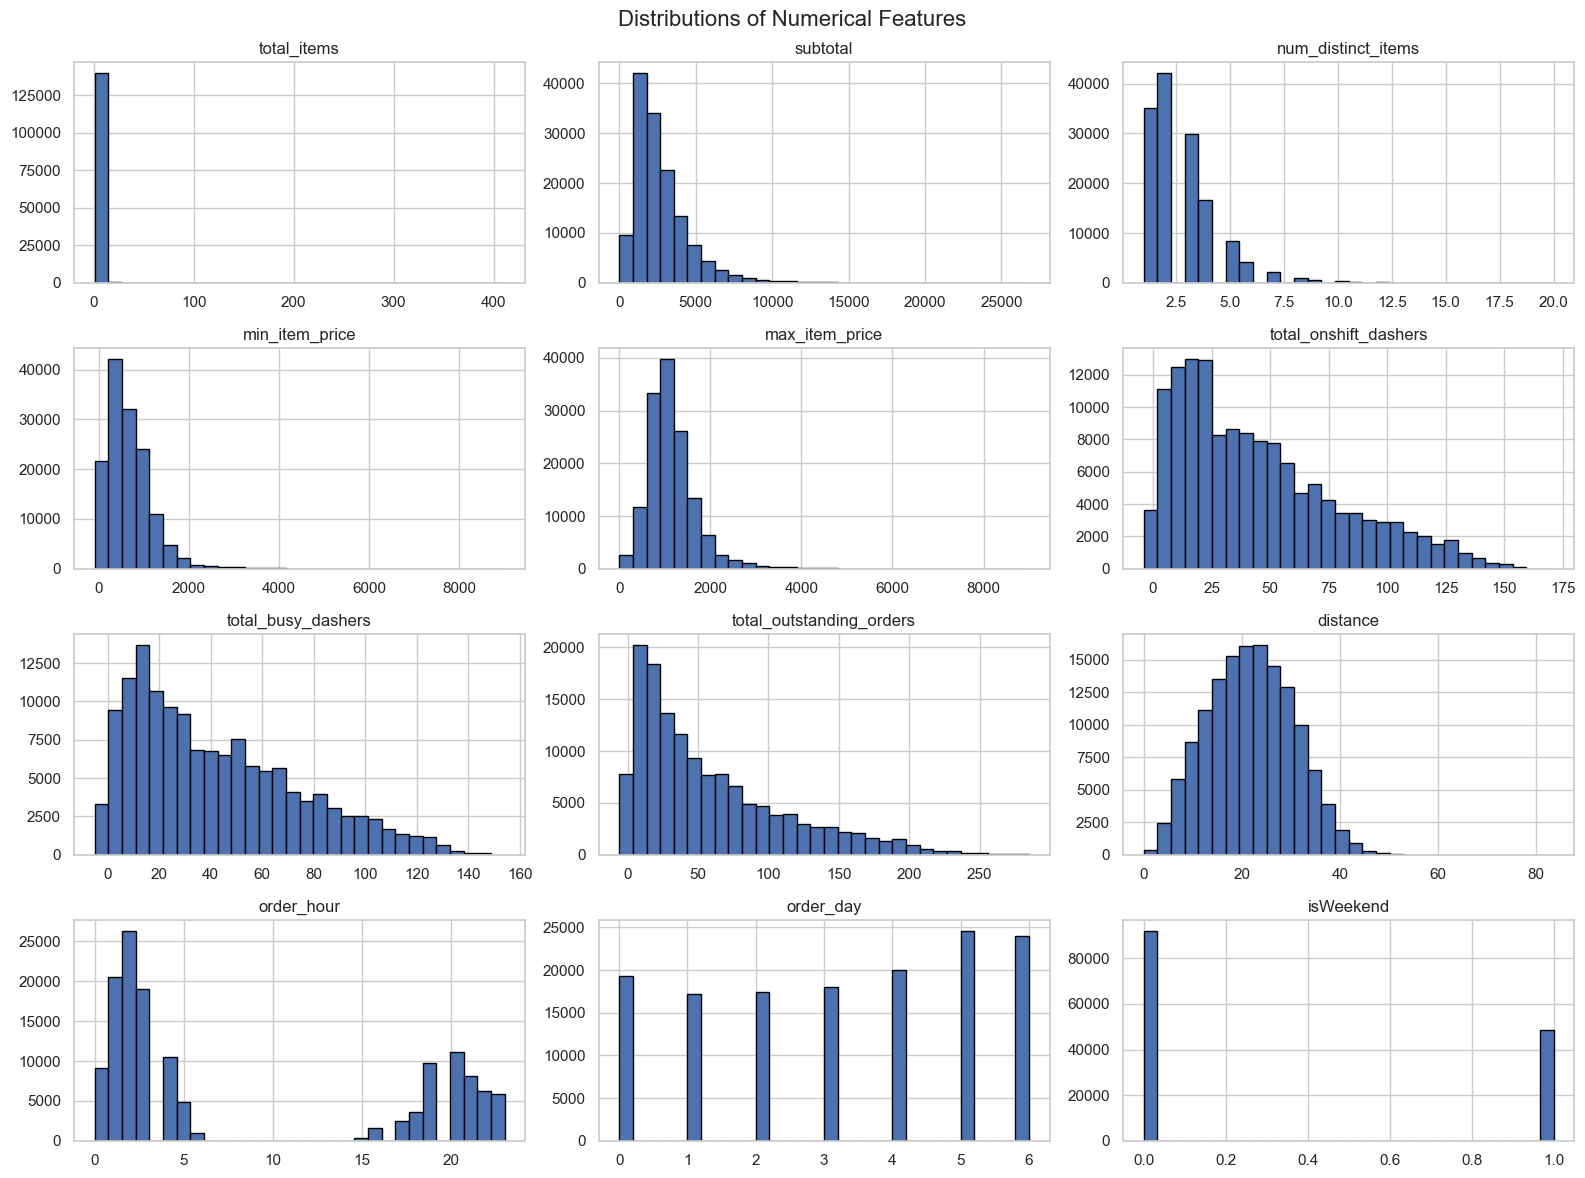

In [40]:
X_train[numerical_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distributions of Numerical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

### Key Observations

The numerical feature distributions reveal several characteristics of the dataset:

* Order-related variables, including `total_items`, `subtotal`, `num_distinct_items`, `min_item_price`, `max_item_price`, and `total_outstanding_orders`, exhibit varying degrees of right skewness.
* The distributions of `total_onshift_dashers` and `total_busy_dashers` indicate substantial variation in dasher availability across orders.
* Delivery distance is concentrated around the middle of its observed range, although some longer-distance orders are present.
* `order_hour` shows variations in order activity across different hours, while `order_day` represents the day of the week on which an order was placed.
* The `isWeekend` feature is binary, distinguishing weekday orders from weekend orders.

These observations help identify patterns that warrant further investigation during data-quality checks and outlier analysis. Unusual values will be investigated before any observations are removed or transformed.


### 4.1.2 Categorical Feature Distributions

Categorical feature distributions are examined to understand how orders are distributed across markets, store categories, and order protocols.

This analysis helps identify dominant categories, infrequent categories, and potential imbalances that may affect feature encoding and model development.


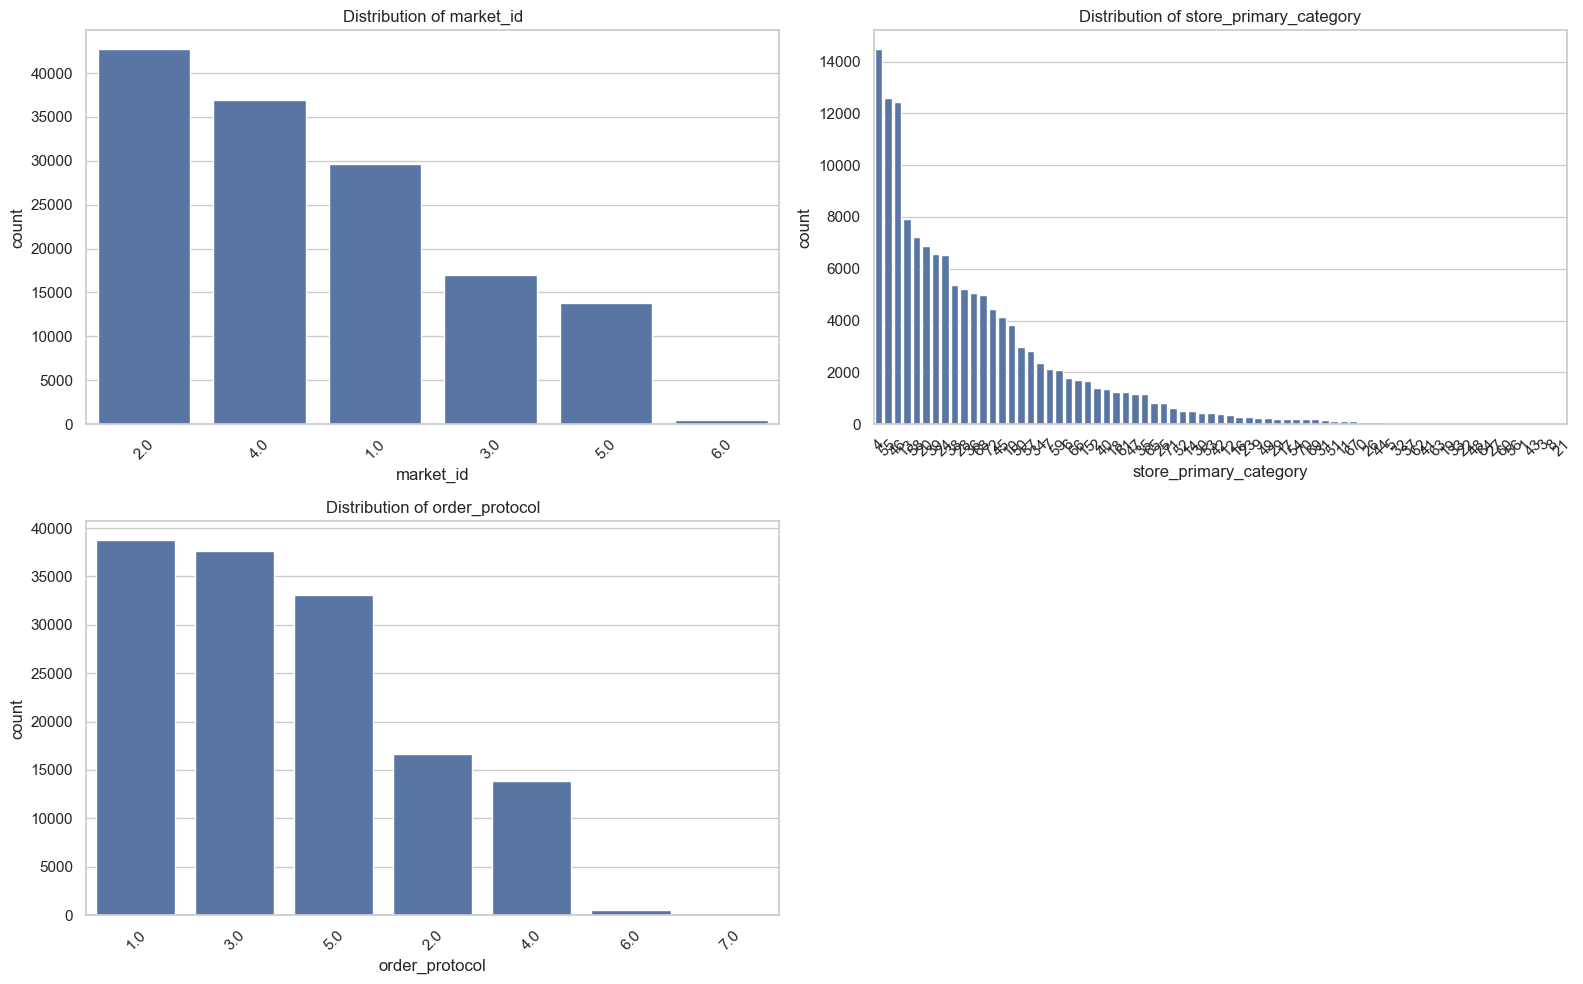

In [21]:
plt.figure(figsize=(16, 10))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(2, 2, i)

    sns.countplot(
        data=X_train,
        x=col,
        order=X_train[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Key Observations

The categorical feature distributions reveal an uneven distribution of orders across markets, store categories, and order protocols.

* **Market distribution:** Market 2 contributes the largest number of observations, while market 6 has comparatively few.
* **Store categories:** A small number of store categories account for a substantial proportion of orders, while many categories have relatively low frequencies.
* **Order protocols:** The distribution is imbalanced, with some protocols occurring considerably more frequently than others.

These patterns will inform subsequent feature analysis and categorical preprocessing. In particular, the model development stage will need to account for infrequent categories without assuming that low frequency makes a category unimportant.


### 4.1.3 Delivery Time Distribution

The target variable, delivery_time, represents the elapsed time between order creation and actual delivery, measured in minutes.

Its distribution is examined to understand typical delivery durations, variability, skewness, and potentially unusual observations. This analysis provides an initial understanding of the prediction target before model development.


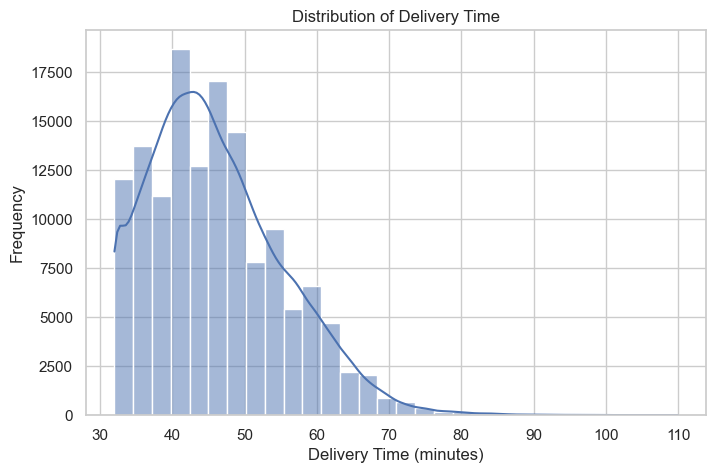

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(y_train, kde=True, bins=30)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Frequency')

plt.show()

#### Key Observations

The delivery-time distribution is concentrated primarily between approximately 35 and 55 minutes, with the highest frequency around 40–45 minutes.

The distribution exhibits positive (right) skewness, with a relatively small number of orders taking substantially longer than the majority of deliveries.

These observations suggest that delivery durations vary across orders and that unusually long deliveries warrant further investigation. Such observations will not be removed solely because they are uncommon; their validity and potential impact on model performance must first be assessed.


## 4.2 Relationship Between Features and Delivery Time

This analysis explores how delivery time varies with selected numerical and categorical features.

Scatter plots are used to investigate relationships between delivery time and numerical variables, while box plots compare delivery-time distributions across categories.

The objective is to identify potential predictive relationships, differences between groups, and patterns that may warrant further investigation. These visual relationships indicate associations and do not, by themselves, establish causation.


### 4.2.1 Relationships Between Numerical Features and Delivery Time

Scatter plots are used to examine the relationship between delivery time and selected numerical features: delivery distance, order subtotal, total on-shift dashers, and total busy dashers.

These visualizations help identify potential trends, variability, and unusual observations. The patterns will guide further investigation into which features may be useful for predicting delivery time.


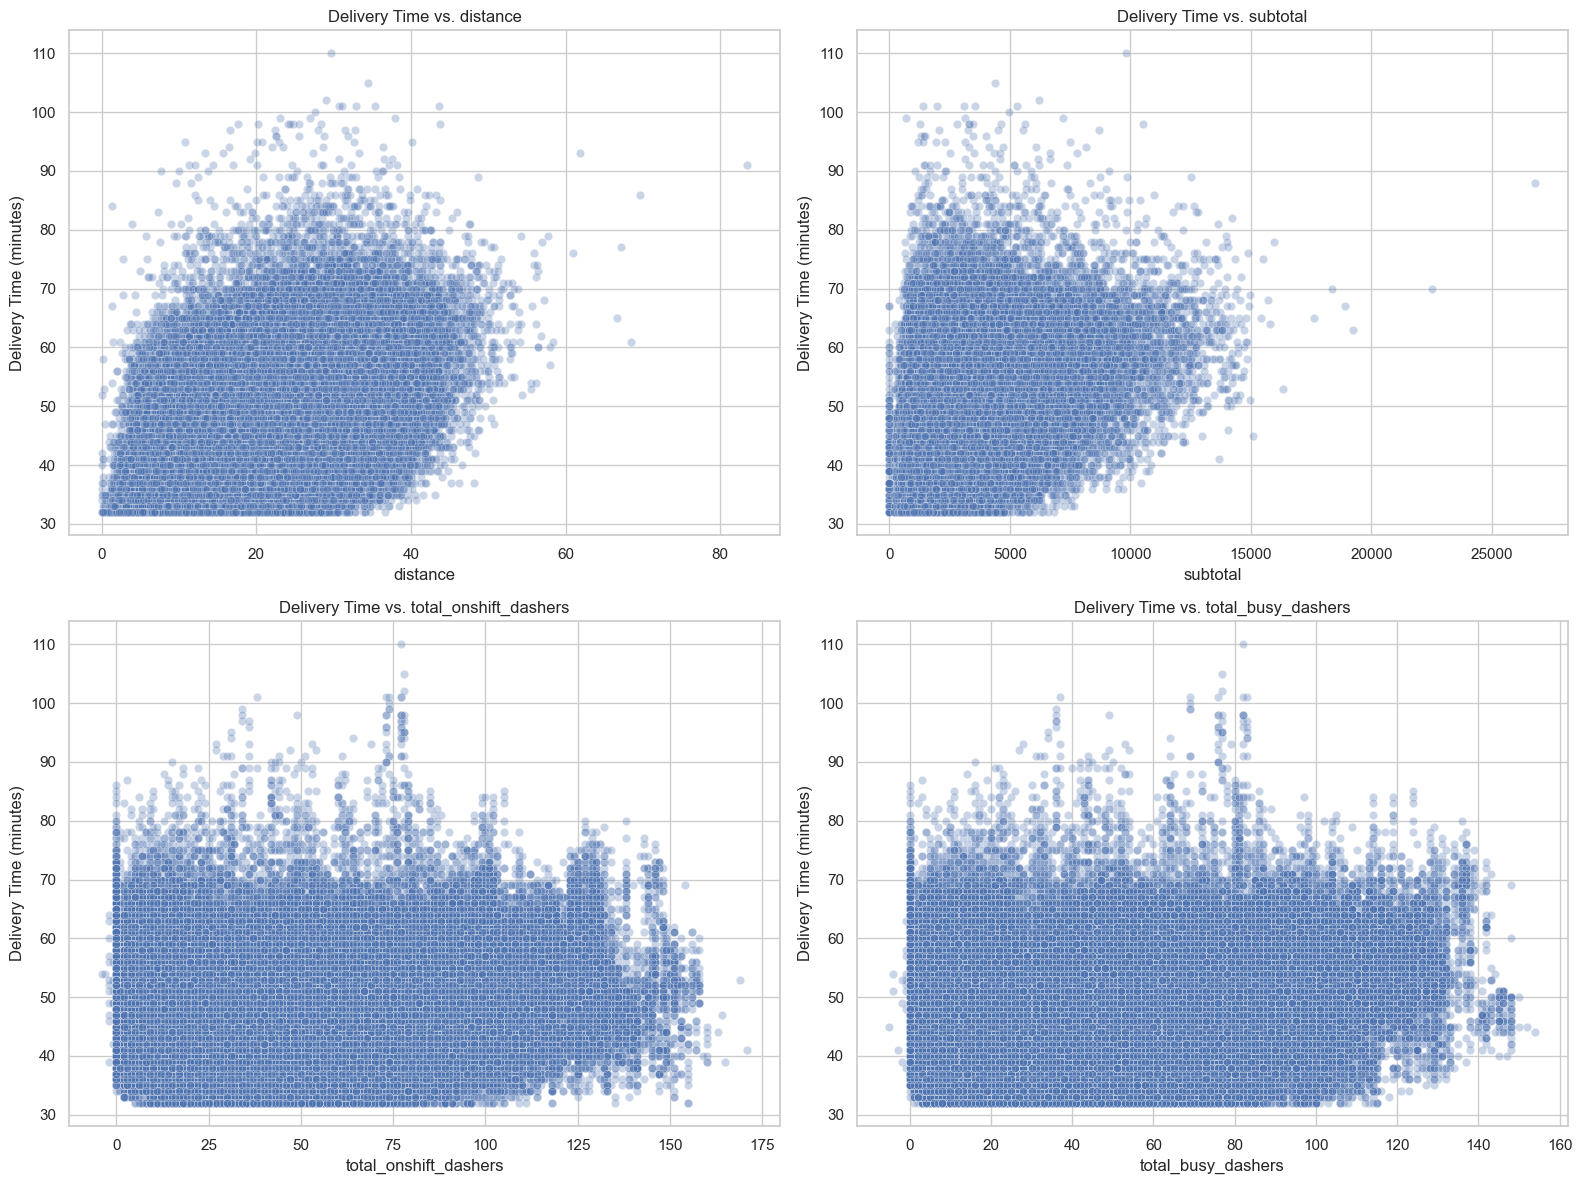

In [23]:
# Explore relationships between numerical features and delivery time

numerical_features = [
    'distance',
    'subtotal',
    'total_onshift_dashers',
    'total_busy_dashers'
]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 2, i)

    sns.scatterplot(
        x=X_train[feature],
        y=y_train,
        alpha=0.3
    )

    plt.title(f'Delivery Time vs. {feature}')
    plt.xlabel(feature)
    plt.ylabel('Delivery Time (minutes)')

plt.tight_layout()
plt.show()

#### Key Observations

The scatter plots reveal the following patterns between numerical features and delivery time:

* **Distance:** Delivery time generally tends to increase with distance, although substantial variability exists among orders with similar distances.
* **Subtotal:** Higher subtotals are associated with a broad range of delivery times, and the relationship does not appear clearly linear.
* **On-shift dashers:** Delivery times vary considerably across different numbers of on-shift dashers, with no obvious consistent linear trend.
* **Busy dashers:** Delivery times show substantial variation across different values of busy dashers, without a clear linear pattern.

These visualizations suggest that distance may be an informative predictor. The relationships involving subtotal and dasher counts require further investigation before drawing conclusions about their predictive value.

The plots show associations rather than causation, and visual patterns alone are insufficient to determine which features should be retained in the final model.


### 4.2.2 Delivery Time Across Categorical Features

Box plots are used to compare delivery-time distributions across markets, store categories, and order protocols.

The analysis examines differences in median delivery time, variability within groups, and potentially unusual observations. These comparisons help identify categorical features that may capture differences in delivery conditions across orders.


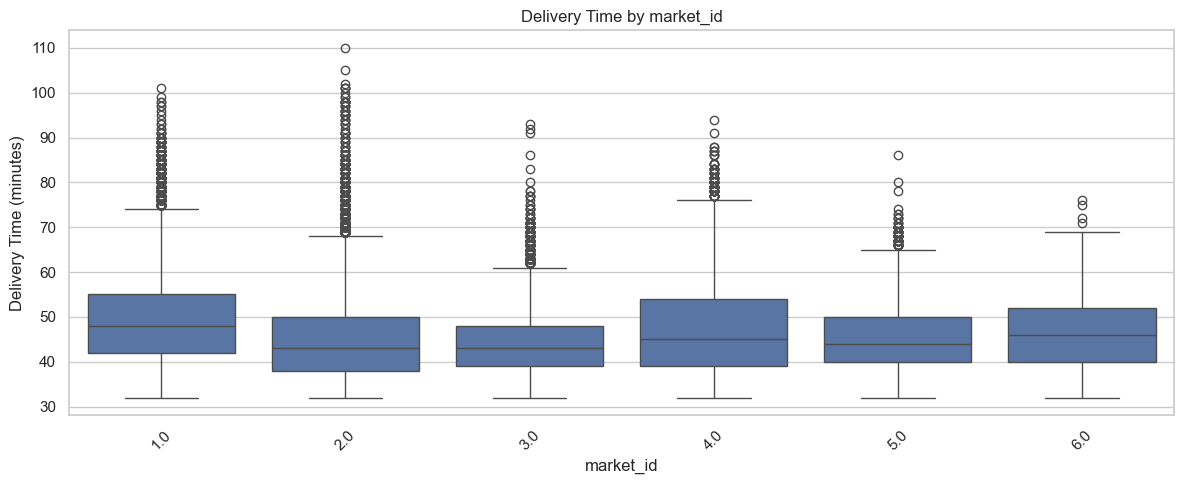

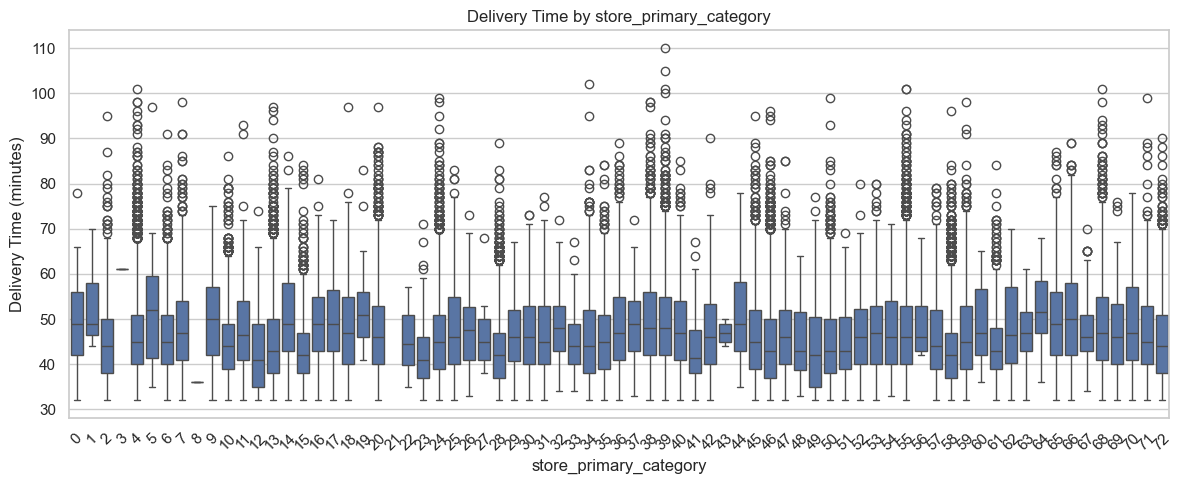

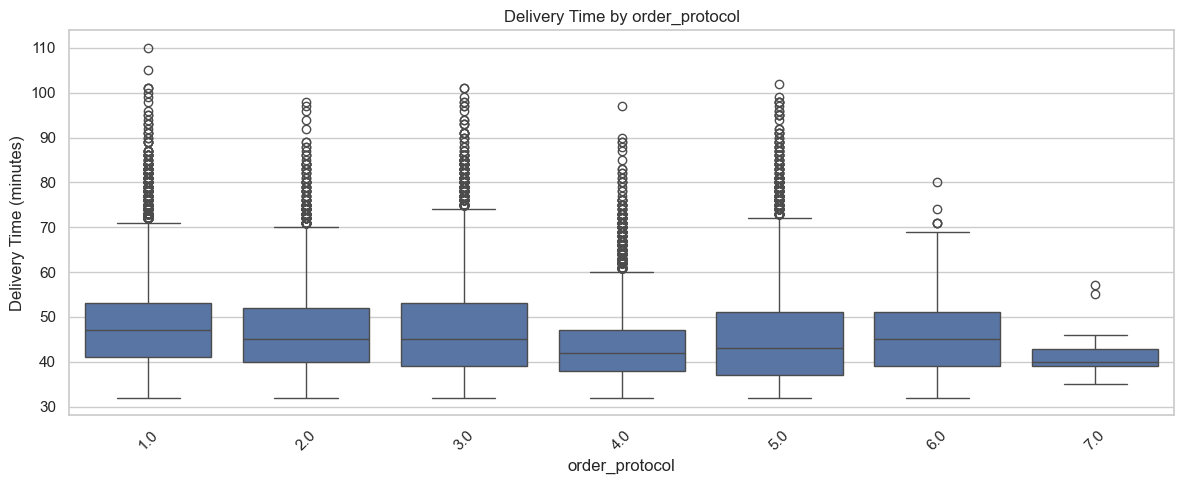

In [24]:
# Compare delivery-time distributions across categorical features

categorical_features = [
    'market_id',
    'store_primary_category',
    'order_protocol'
]

for feature in categorical_features:
    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=X_train,
        x=feature,
        y=y_train
    )

    plt.title(f'Delivery Time by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Delivery Time (minutes)')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

#### Key Observations

The box plots reveal differences in delivery-time distributions across markets, store categories, and order protocols.

* **Market:** Median delivery times and variability differ across markets, suggesting that market-level differences may provide useful predictive information.
* **Store category:** Delivery-time distributions vary across categories, although the large number of categories makes direct visual comparison difficult.
* **Order protocol:** Median delivery times and variability differ between protocols. Some protocols have substantially fewer observations, so their distributions should be interpreted cautiously.

These findings suggest that categorical features may contribute useful information to the prediction model. Further analysis and model evaluation will be required to determine their actual predictive value.


## 4.3 Correlation Analysis

Correlation analysis is used to examine the strength and direction of linear relationships between numerical features and delivery time.

A correlation matrix provides an overview of relationships between individual features and can also highlight potential multicollinearity, where two or more predictors are strongly correlated with each other.

Correlation measures linear association and does not establish causation. Features with weak individual correlations will not automatically be excluded, as they may still contribute useful predictive information when combined with other variables.


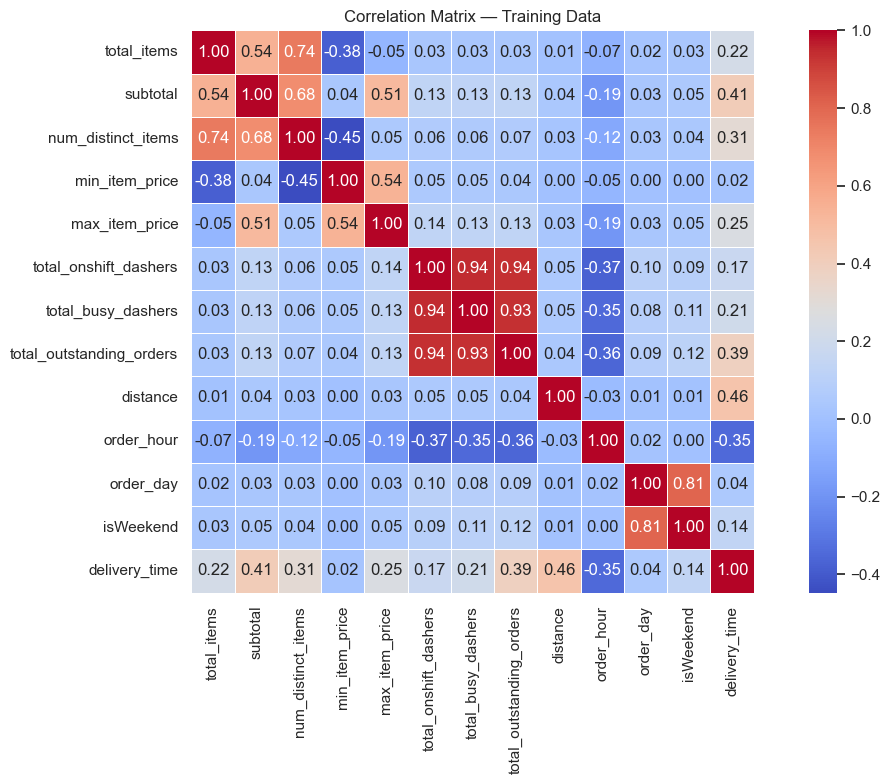

In [25]:
# Combine training features and target for correlation analysis

train_data = X_train.copy()
train_data['delivery_time'] = y_train

# Calculate correlations between numerical variables
corr_matrix = train_data.corr(numeric_only=True)

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=0.5
)

plt.title('Correlation Matrix — Training Data')
plt.tight_layout()
plt.show()

#### Key Observations

The correlation matrix highlights several relationships between numerical features and delivery time.

* **Distance:** Has the strongest positive linear correlation with delivery time among the displayed features (approximately 0.46).
* **Subtotal and outstanding orders:** Both show positive correlations with delivery time, at approximately 0.41 and 0.39, respectively.
* **Order hour:** Shows a negative correlation of approximately -0.35. Because time of day is cyclical, this relationship requires careful interpretation.
* **Minimum item price:** Has almost no linear correlation with delivery time, although this alone does not establish that the feature lacks predictive value.

The matrix also reveals strong correlations between several input features. Dasher counts and outstanding orders have pairwise correlations above 0.90, while `order_day` and `isWeekend` have a correlation of approximately 0.81.

These relationships suggest potential multicollinearity and overlapping information among predictors. Feature-selection decisions will consider the meaning and availability of each feature, as well as model performance, rather than relying solely on individual correlations.


## 4.4 Outlier Analysis

Outlier analysis is used to identify observations that differ substantially from the majority of the dataset.

In delivery-time prediction, unusual values may represent data-quality issues or legitimate situations, such as unusually large orders, long delivery distances, or extended delivery durations.

Box plots will be used to identify potentially unusual observations across the target variable and numerical features. These observations will then be investigated before deciding whether any treatment is necessary.

The objective is to improve data quality without unnecessarily removing valid information.


### 4.4.1 Delivery-Time Outlier Visualization

A box plot is used to examine the distribution of delivery time and identify observations that fall beyond the typical range.

The plot highlights the median, interquartile range, whiskers, and potential outliers. Values identified as outliers are candidates for further investigation rather than automatic removal.


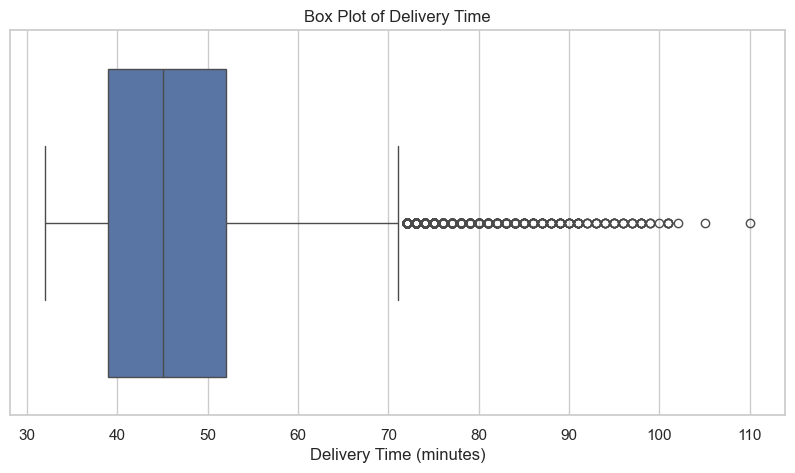

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=y_train)

plt.title('Box Plot of Delivery Time')
plt.xlabel('Delivery Time (minutes)')

plt.show()

#### Key Observations

The delivery-time box plot shows that the median delivery duration is approximately 45 minutes, with the middle 50% of observations concentrated between roughly 39 and 52 minutes.

The upper whisker extends to approximately 71 minutes, beyond which numerous observations are identified as potential outliers. Some delivery times exceed 100 minutes.

These observations indicate a right-skewed distribution with a number of unusually long deliveries. However, the box plot alone cannot distinguish legitimate long deliveries from data-quality errors. Further investigation is required before deciding whether any observations should be removed or transformed.


### 4.4.2 Numerical Feature Outlier Visualization

Box plots are used to examine the numerical input features and identify observations that fall outside their typical ranges.

The analysis focuses on variables such as order size, subtotal, item prices, dasher availability, outstanding orders, and delivery distance.

Potential outliers will be investigated in the context of each feature. Observations will not be removed solely because they fall outside the standard interquartile-range boundaries.


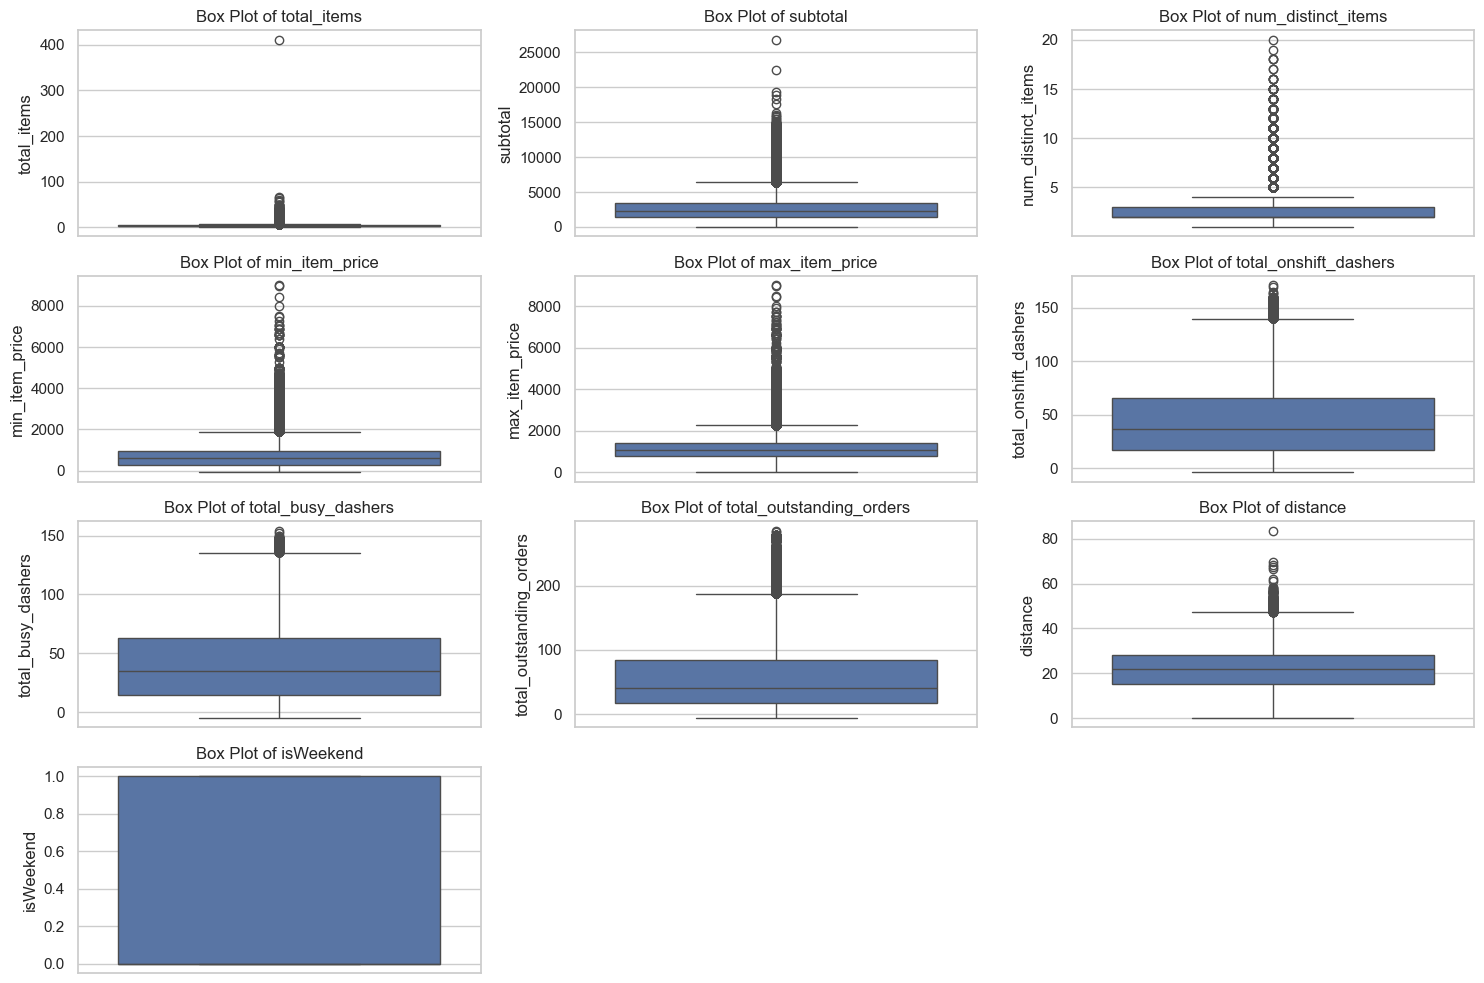

In [27]:
# Identify numerical features in the training dataset
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Plot box plots for numerical features
plt.figure(figsize=(15, 10))

for i, col in enumerate(numeric_features, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=X_train[col])
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

#### Key Observations

The box plots reveal potential outliers across several numerical features, including order size, subtotal, item prices, dasher counts, outstanding orders, and delivery distance.

Many features exhibit upper-tail outliers, indicating that a relatively small number of observations have values substantially higher than those of the majority of orders.

These observations may represent legitimate variation in order characteristics or potential data-quality issues. The box plots alone cannot distinguish between these possibilities.

The binary `isWeekend` feature is not meaningfully assessed using continuous outlier rules.

Further investigation is required before selecting an outlier-treatment strategy. Valid observations should be retained wherever possible to preserve useful information for model training.


### 4.4.3 Quantifying Potential Outliers

The interquartile range (IQR) method is used to estimate the number and proportion of observations outside the typical range of each numerical feature.

For each feature, the lower boundary is calculated as Q1 − 1.5 × IQR, and the upper boundary as Q3 + 1.5 × IQR.

This analysis quantifies potentially unusual observations without removing or modifying any data. The results will inform subsequent data-quality checks and outlier-treatment decisions.


In [28]:
# Quantify potential outliers using the IQR rule

outlier_summary = []

for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Potential Outliers': outlier_count,
        'Outlier Percentage': round(
            outlier_count / len(X_train) * 100, 2
        )
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df

,Feature,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,total_items,-1.00,7.00,6803,4.84
1,subtotal,-1577.50,6410.50,6474,4.60
2,num_distinct_items,0.50,4.50,16678,11.86
3,min_item_price,-662.50,1901.50,3262,2.32
4,max_item_price,-95.00,2289.00,5515,3.92
5,total_onshift_dashers,-56.50,139.50,972,0.69
6,total_busy_dashers,-57.00,135.00,366,0.26
7,total_outstanding_orders,-85.00,187.00,4184,2.98
8,distance,-3.88,47.32,264,0.19
9,isWeekend,-1.50,2.50,0,0.00


#### Key Observations

The IQR-based analysis identifies potential outliers across several numerical features. The highest proportion occurs in `num_distinct_items` (11.86%), followed by `total_items` (4.84%) and `subtotal` (4.60%).

In contrast, only 0.19% of observations are flagged for `distance`, while no observations are flagged for the binary `isWeekend` feature.

These results demonstrate that the IQR method identifies values outside the central distribution, but it does not establish whether those values are invalid. Consequently, the flagged observations will not be removed automatically.

Further data-quality checks will be used to investigate implausible values before selecting an appropriate treatment strategy.


### 4.4.4 Numerical Data Quality Checks

Before applying any outlier-treatment strategy, numerical features are checked for values that violate basic domain constraints.

This step distinguishes potentially invalid observations, such as negative item counts or distances, from legitimate extreme values. The results will inform subsequent data-cleaning decisions without automatically removing observations.


In [29]:
# Check numerical features for negative values

non_negative_cols = [
    'total_items',
    'subtotal',
    'num_distinct_items',
    'min_item_price',
    'max_item_price',
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders',
    'distance'
]

negative_value_counts = (
    X_train[non_negative_cols] < 0
).sum()

print("Negative value counts:")
print(negative_value_counts)

Negative value counts:
total_items                  0
subtotal                     0
num_distinct_items           0
min_item_price              11
max_item_price               0
total_onshift_dashers       20
total_busy_dashers          16
total_outstanding_orders    34
distance                     0
dtype: int64


The numerical data-quality check identified negative values in four features: min_item_price (11 observations), total_onshift_dashers (20 observations), total_busy_dashers (16 observations), and total_outstanding_orders (34 observations).

In [30]:
# Identify rows containing negative values in the affected features

affected_cols = [
    'min_item_price',
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders'
]

negative_mask = (X_train[affected_cols] < 0).any(axis=1)

print("Rows containing at least one negative value:", negative_mask.sum())

X_train.loc[negative_mask, affected_cols].head(20)

Rows containing at least one negative value: 76


,min_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders
170680,266,8.0,-2.0,8.0
166561,-52,15.0,13.0,15.0
42676,295,6.0,-1.0,8.0
39567,126,24.0,8.0,-2.0
5535,1238,-2.0,2.0,10.0
41264,-48,36.0,36.0,43.0
92702,-30,18.0,23.0,12.0
59467,1093,0.0,-4.0,6.0
106422,110,-2.0,-1.0,11.0
84181,117,3.0,5.0,-6.0


#### Quantifying Potentially Invalid Values

The affected numerical features are examined individually to determine the number and proportion of observations containing negative values.

This analysis helps assess the extent of the data-quality issue and whether the affected records overlap across features. The results will guide subsequent cleaning decisions.


In [31]:
# Summarize negative values in each affected feature

negative_summary = pd.DataFrame({
    'Negative Value Count': (X_train[affected_cols] < 0).sum(),
    'Percentage of Training Data': (
        (X_train[affected_cols] < 0).sum()
        / len(X_train) * 100
    ).round(3)
})

negative_summary

,Negative Value Count,Percentage of Training Data
min_item_price,11,0.008
total_onshift_dashers,20,0.014
total_busy_dashers,16,0.011
total_outstanding_orders,34,0.024


Findings from Numerical Data Quality Checks

The analysis identified 76 training observations containing at least one negative value across min_item_price, total_onshift_dashers, total_busy_dashers, and total_outstanding_orders.

Although these observations represent a small proportion of the training dataset, negative item prices and negative counts are potentially invalid. The available checks do not establish how these values originated or whether they can be corrected reliably.

In [32]:
# Count zero values in numerical features

zero_value_counts = (X_train[non_negative_cols] == 0).sum()

print("Zero value counts:")
print(zero_value_counts)

Zero value counts:
total_items                    0
subtotal                     132
num_distinct_items             0
min_item_price              1753
max_item_price                 6
total_onshift_dashers       2871
total_busy_dashers          3286
total_outstanding_orders    3241
distance                       8
dtype: int64


#### Findings from Zero-Value Checks

The zero-value analysis identified observations with zero subtotals, item prices, dasher counts, outstanding-order counts, and delivery distances.

The highest count occurs in `min_item_price`, with 1,753 zero values. The operational count features also contain several thousand zero values, which may be valid depending on their definitions and the circumstances of an order.

Only eight observations have zero distance, while six have zero `max_item_price`.

Zero values will not be treated as invalid automatically. Their interpretation depends on the meaning of each feature and the context of the affected observations. Further investigation will guide any necessary cleaning decisions.


In [33]:
# Inspect records with zero minimum item price
print("Records with zero minimum item price:")

display(
    X_train.loc[
        X_train['min_item_price'] == 0,
        [
            'total_items',
            'subtotal',
            'num_distinct_items',
            'min_item_price',
            'max_item_price',
            'distance'
        ]
    ].head(10)
)

# Inspect records with zero distance
print("Records with zero distance:")

display(
    X_train.loc[
        X_train['distance'] == 0,
        [
            'total_items',
            'subtotal',
            'num_distinct_items',
            'min_item_price',
            'max_item_price',
            'distance'
        ]
    ]
)

Records with zero minimum item price:


,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,distance
27002,5,5340,4,0,1450,20.76
81206,13,1415,5,0,159,35.08
164282,4,3207,3,0,1209,14.60
89901,3,2399,2,0,2399,17.40
41483,3,3597,3,0,2099,23.08
12475,11,1065,4,0,329,15.28
168063,6,1314,4,0,600,30.44
77601,14,726,5,0,249,12.08
142567,3,3800,2,0,1550,17.16
128710,4,998,2,0,499,18.28


Records with zero distance:


,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,distance
31782,5,3390,4,100,830,0.0
86435,2,3490,2,1495,1995,0.0
51110,4,3082,3,695,895,0.0
52095,4,1815,3,335,795,0.0
50386,3,2187,2,695,797,0.0
140320,5,7200,3,1000,1400,0.0
159736,7,6875,7,229,1181,0.0
141376,4,2722,4,275,1199,0.0


#### Investigation of Zero Item Prices and Delivery Distances

Inspection of individual records identified two types of observations requiring further investigation.

* **Zero minimum item prices:** Some orders contain multiple items and a positive subtotal despite having a recorded minimum item price of zero. The available data does not establish whether these values represent legitimate free items or data-quality issues.
* **Zero delivery distances:** Eight training observations have a recorded distance of zero despite containing orders with positive subtotals and item prices. The original distance-calculation method is not yet known.

These observations will be retained for now. Their treatment will depend on the dataset's definitions and whether the values can be verified as valid or invalid.


In [34]:
# Check for zero and negative delivery times

print("Negative delivery times:", (y_train < 0).sum())
print("Zero delivery times:", (y_train == 0).sum())

print("\nDelivery-time summary:")
print(y_train.describe())

Negative delivery times: 0
Zero delivery times: 0

Delivery-time summary:
count    140621.000000
mean         46.198071
std           9.320360
min          32.000000
25%          39.000000
50%          45.000000
75%          52.000000
max         110.000000
Name: delivery_time, dtype: float64


#### Target Variable Quality Assessment

The training target contains 140,621 observations, with no zero or negative delivery times detected.

The mean delivery time is approximately 46.20 minutes, while the median is 45 minutes. The difference between these statistics is consistent with the right-skewed distribution observed during exploratory analysis.

Delivery times range from 32 to 110 minutes, with a standard deviation of approximately 9.32 minutes.

Although the target passes the initial zero and negative value checks, unusually long deliveries still warrant investigation. Extreme values will not be removed solely because they are far from the median.


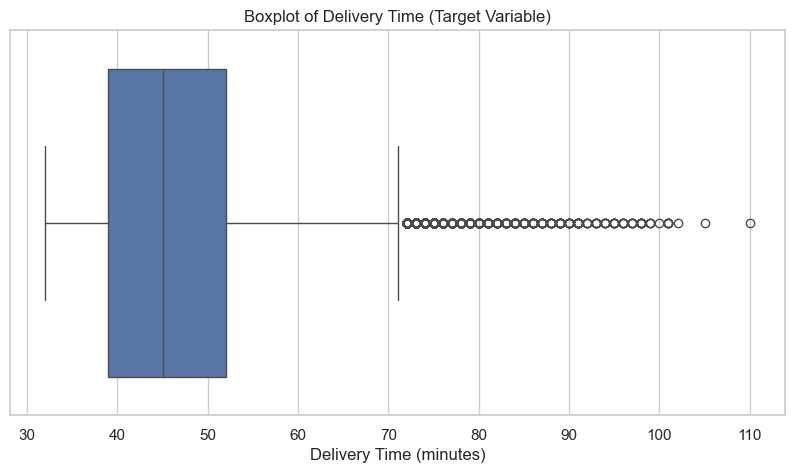

In [41]:
# Boxplot for the target variable
plt.figure(figsize=(10, 5))

sns.boxplot(x=y_train)
plt.title('Boxplot of Delivery Time (Target Variable)')
plt.xlabel('Delivery Time (minutes)')
plt.show()

### Observations: Target Variable

The delivery-time boxplot shows a median of approximately 45 minutes, with the middle 50% of observations concentrated between approximately 39 and 52 minutes. The upper whisker extends to around 71 minutes, beyond which several potential outliers are visible. The longest observed delivery times approach 110 minutes.

These observations indicate a right-skewed distribution with a small number of unusually long deliveries. Since these values may represent genuine operational delays, they should be investigated before any observations are removed.


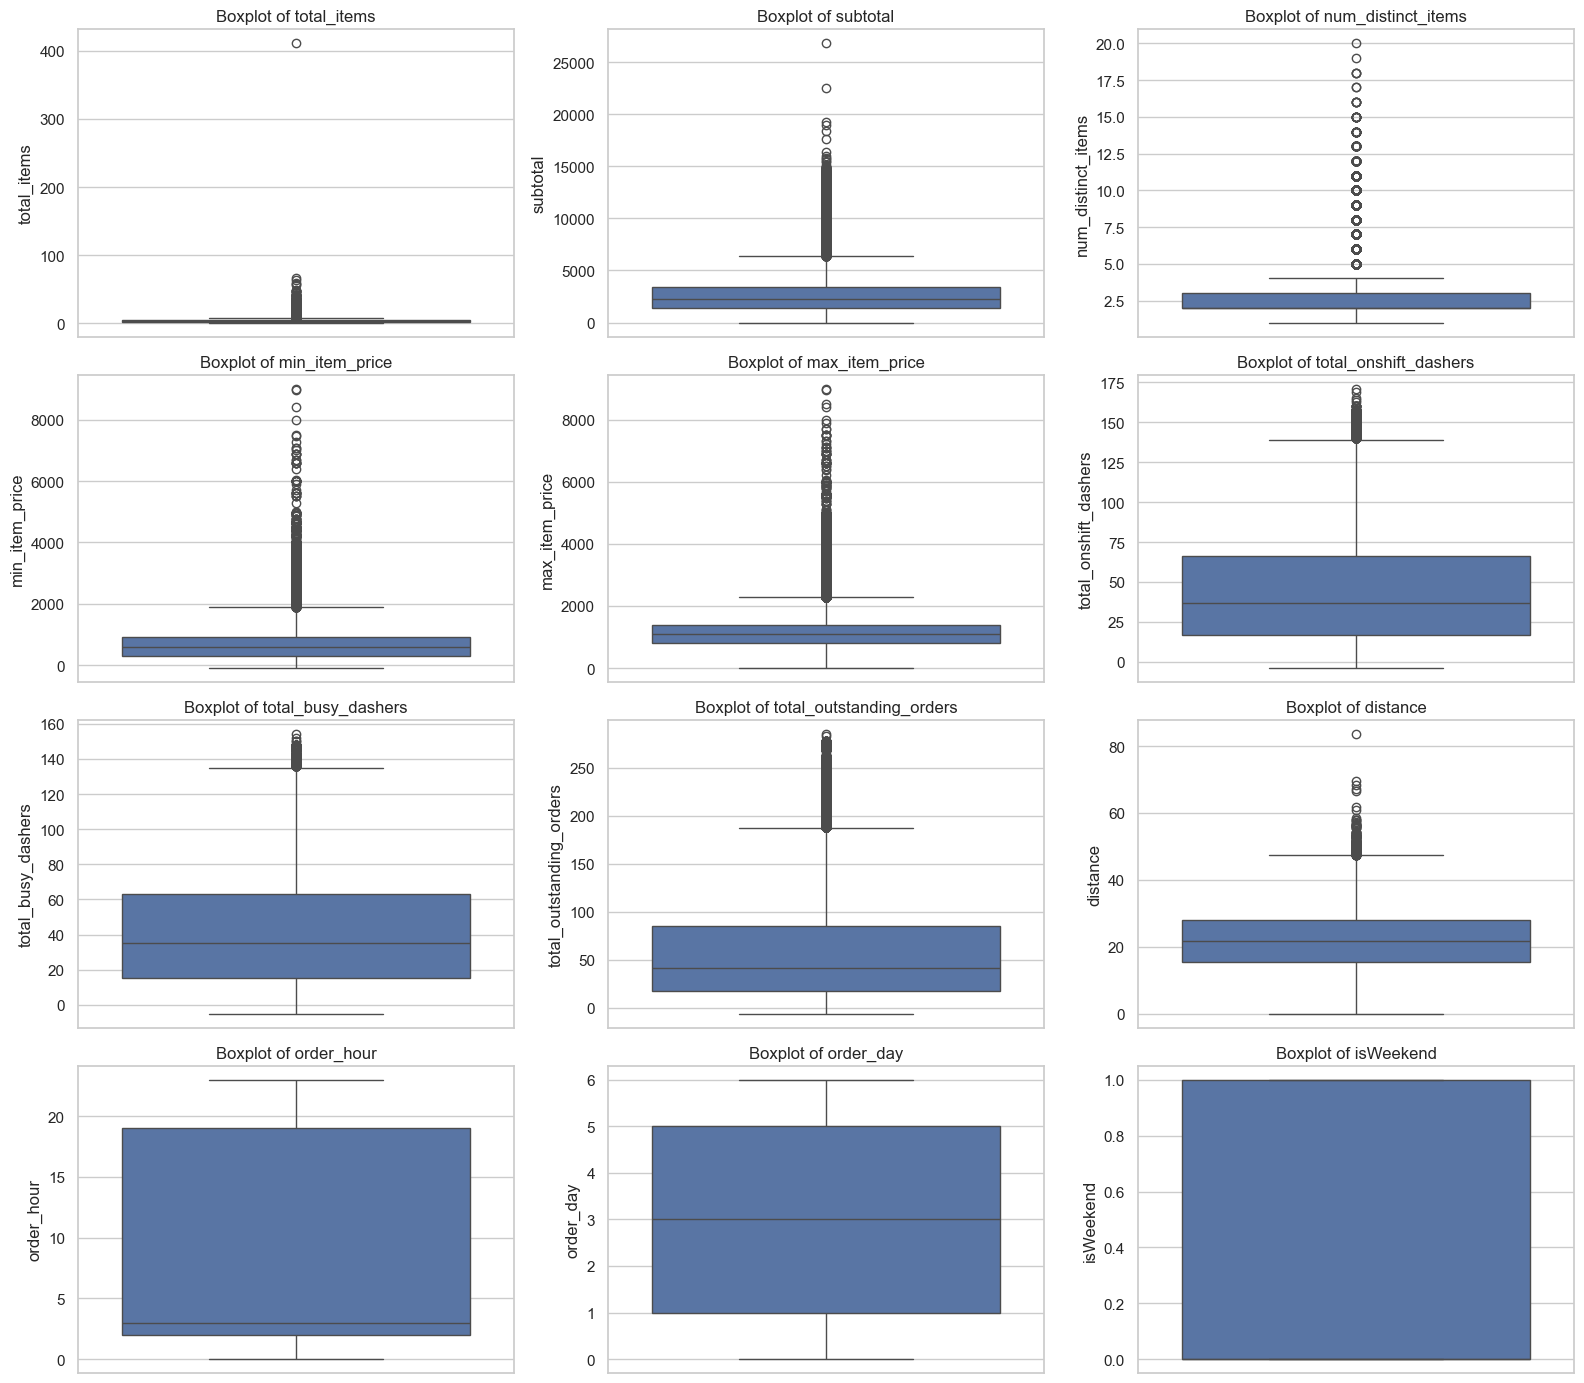

In [43]:
# Boxplots for all numerical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns

# Create a 4-row, 3-column grid for 12 features
plt.figure(figsize=(16, 14))

for i, col in enumerate(numeric_features, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(y=X_train[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

### Observations: Numerical Feature Outliers

The boxplots indicate potential outliers across several numerical features, including order quantities, prices, dasher availability, outstanding orders, and delivery distance.

Several features contain observations extending beyond their upper whiskers, indicating unusually high values relative to their interquartile ranges.

However, these observations are not necessarily data errors. Some may represent legitimate orders with unusually large quantities, higher prices, greater delivery distances, or periods of high operational demand. These values should be investigated before deciding whether to remove or transform them.


### Calculate IQR outlier counts
The Interquartile Range (IQR) method is used to identify potential outliers in the training dataset. Observations outside the IQR boundaries will be evaluated before removal to avoid discarding legitimate orders.

In [45]:
# Calculate potential outliers in numerical predictors
outlier_summary = []

for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    )

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': int(outlier_mask.sum()),
        'Outlier Percentage': round(
            outlier_mask.mean() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    by='Outlier Percentage',
    ascending=False
)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
2,num_distinct_items,0.50,4.50,16678,11.86
0,total_items,-1.00,7.00,6803,4.84
1,subtotal,-1577.50,6410.50,6474,4.60
4,max_item_price,-95.00,2289.00,5515,3.92
7,total_outstanding_orders,-85.00,187.00,4184,2.98
3,min_item_price,-662.50,1901.50,3262,2.32
5,total_onshift_dashers,-56.50,139.50,972,0.69
6,total_busy_dashers,-57.00,135.00,366,0.26
8,distance,-3.88,47.32,264,0.19
9,order_hour,-23.50,44.50,0,0.00


### Outlier Treatment Decision

IQR analysis identified potential outliers across several numerical features. Since extreme values may represent legitimate business scenarios, they will not be removed automatically. Potential data-quality errors will be investigated separately, and the impact of outlier treatment will be evaluated during model development.


## **5. Model Building** 

In [47]:
# Confirm the training and test datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (140621, 15)
Testing features: (35156, 15)
Training target: (140621,)
Testing target: (35156,)


#### **Import Necessary Libraries**

In [48]:
# Import libraries

from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor



### 5.1 Feature Scaling

Numerical features are standardized to place variables with different scales on a comparable basis. The scaler is fitted using the training data and then applied to both training and test data to prevent information leakage.


In [49]:
# Apply scaling to the numerical columns
# Select numerical columns for scaling
numerical_cols = ['total_items', 'subtotal', 'num_distinct_items',
                  'max_item_price', 'order_hour', 'total_outstanding_orders', 'distance']

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform the numerical features in training and testing sets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])



Note that linear regression is agnostic to feature scaling. However, with feature scaling, we get the coefficients to be somewhat on the same scale so that it becomes easier to compare them.

#### 5.2 Build a linear regression model

You can choose from the libraries *statsmodels* and *scikit-learn* to build the model.

In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict delivery time
y_pred = lr_model.predict(X_test_scaled)

# Evaluate performance
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²):", round(r2, 4))

Root Mean Squared Error (RMSE): 3.22
R-squared (R²): 0.8813


### Baseline Model Performance

The Linear Regression model achieved an RMSE of 3.22 minutes and an R² of 0.8813 on the held-out test set. These results establish the current baseline for comparison with subsequent feature-selection experiments.


### 5.3 Recursive Feature Elimination (RFE)

Recursive Feature Elimination (RFE) identifies a subset of predictive features by repeatedly training a model and removing the least important features. Different subset sizes will be evaluated to identify a suitable balance between model simplicity and predictive performance.


In [53]:
from sklearn.model_selection import train_test_split

X_train_rfe, X_val_rfe, y_train_rfe, y_val_rfe = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42
)

print("RFE training features:", X_train_rfe.shape)
print("Validation features:", X_val_rfe.shape)

RFE training features: (112496, 15)
Validation features: (28125, 15)


In [54]:
feature_counts = range(1, X_train_rfe.shape[1] + 1)
rfe_results = []

for n_features in feature_counts:
    selector = RFE(
        estimator=LinearRegression(),
        n_features_to_select=n_features
    )

    selector.fit(X_train_rfe, y_train_rfe)

    selected_features = X_train_rfe.columns[selector.support_]

    model = LinearRegression()
    model.fit(X_train_rfe[selected_features], y_train_rfe)

    val_predictions = model.predict(X_val_rfe[selected_features])

    rmse = np.sqrt(
        mean_squared_error(y_val_rfe, val_predictions)
    )

    rfe_results.append({
        'Number of Features': n_features,
        'Validation RMSE': rmse,
        'Selected Features': list(selected_features)
    })

rfe_results_df = pd.DataFrame(rfe_results)

rfe_results_df[
    ['Number of Features', 'Validation RMSE']
].sort_values('Validation RMSE')

,Number of Features,Validation RMSE
14,15,3.194941
13,14,3.195520
12,13,3.198443
11,12,3.199399
10,11,3.202508
9,10,3.475323
8,9,3.485306
7,8,6.324583
6,7,6.407879
5,6,6.426847


In [56]:
best_result = rfe_results_df.loc[
    rfe_results_df['Validation RMSE'].idxmin()
]

print("Best number of features:", best_result['Number of Features'])
print("Best validation RMSE:", round(best_result['Validation RMSE'], 4))
print("Selected features:", best_result['Selected Features'])

Best number of features: 15
Best validation RMSE: 3.1949
Selected features: ['market_id', 'store_primary_category', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'distance', 'order_hour', 'order_day', 'isWeekend']


In [57]:


# Train the final model using all training data
final_model = LinearRegression()
final_model.fit(X_train_scaled, y_train)

# Evaluate on the untouched test set
y_pred_final = final_model.predict(X_test_scaled)

final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_r2 = r2_score(y_test, y_pred_final)

print("Final Test RMSE:", round(final_rmse, 4))
print("Final Test R²:", round(final_r2, 4))

Final Test RMSE: 3.2238
Final Test R²: 0.8813


## **6. Results and Inference** 

### Residual Analysis

Residual analysis examines the differences between actual and predicted delivery times. It helps identify systematic prediction errors, patterns that the model has not captured, and observations with unusually large errors.


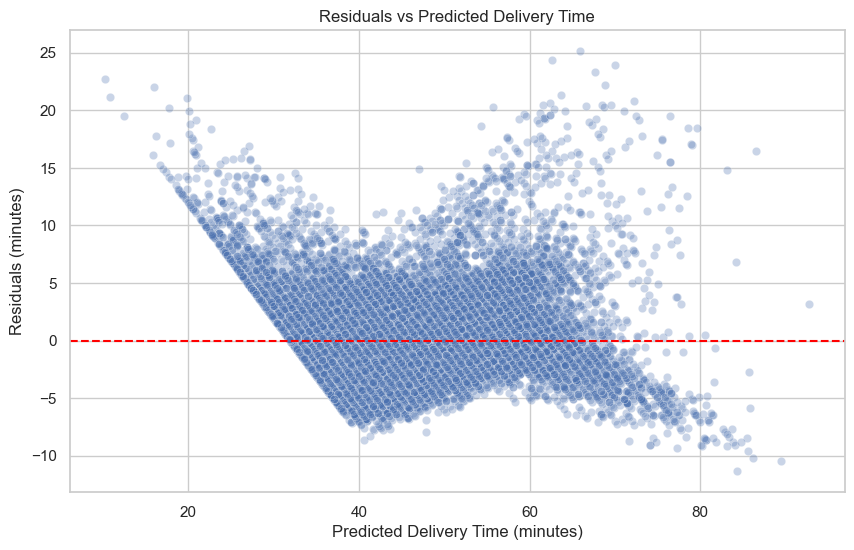

In [58]:

# Calculate residuals
residuals = y_test - y_pred_final

# Plot residuals against predicted values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred_final, y=residuals, alpha=0.3)

plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Predicted Delivery Time')
plt.xlabel('Predicted Delivery Time (minutes)')
plt.ylabel('Residuals (minutes)')
plt.show()

The residual plot shows a clear pattern rather than random scatter around zero, suggesting that the model may not fully capture the relationship between the predictors and delivery time. The changing spread of residuals also indicates possible heteroscedasticity. These findings suggest that the Linear Regression model's errors vary across predicted delivery times.


#### Perform Coefficient Analysis

In [59]:
# Fit a linear regression model on the original feature scales
coefficient_model = LinearRegression()
coefficient_model.fit(X_train, y_train)

# Create a coefficient table
coeff_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coefficient_model.coef_
})

# Sort by absolute coefficient magnitude
coeff_df['Absolute Coefficient'] = coeff_df['Coefficient'].abs()
coeff_df = coeff_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

print(coeff_df)

                     Feature  Coefficient  Absolute Coefficient
14                 isWeekend     1.633413              1.633413
2             order_protocol    -0.678400              0.678400
0                  market_id    -0.621492              0.621492
5         num_distinct_items     0.572252              0.572252
11                  distance     0.476393              0.476393
8      total_onshift_dashers    -0.359322              0.359322
10  total_outstanding_orders     0.346197              0.346197
12                order_hour    -0.247910              0.247910
9         total_busy_dashers    -0.142567              0.142567
13                 order_day    -0.118727              0.118727
3                total_items    -0.038517              0.038517
1     store_primary_category     0.005771              0.005771
4                   subtotal     0.001245              0.001245
7             max_item_price     0.000565              0.000565
6             min_item_price     0.00020

The coefficients describe how each feature relates to predicted delivery time when other features are held constant. Positive coefficients indicate an increase in predicted delivery time, while negative coefficients indicate a decrease.

`isWeekend` has the largest positive coefficient (1.633), while `order_protocol` has the largest negative coefficient (-0.678). However, coefficients for features measured on different scales cannot be directly compared to determine their relative importance. Categorical variables also require careful interpretation depending on how they are encoded.


In [61]:
# Select the feature to analyse
feature_name = 'num_distinct_items'

# Get its coefficient from the unscaled model
coefficient = coefficient_model.coef_[
    list(X_train.columns).index(feature_name)
]

print(
    f"A one-unit increase in '{feature_name}' is associated with "
    f"a {coefficient:.4f}-minute change in predicted delivery time, "
    "holding other features constant."
)

A one-unit increase in 'num_distinct_items' is associated with a 0.5723-minute change in predicted delivery time, holding other features constant.


# Project Findings & Business Recommendations

## Key Findings

### 1. Factors Associated with Delivery Time

Exploratory data analysis identified several features associated with delivery time. Distance showed a positive correlation of approximately 0.46, while order subtotal showed a positive correlation of approximately 0.41. Total outstanding orders had a positive correlation of approximately 0.39. These relationships suggest that delivery time is associated with both delivery conditions and order characteristics.

Order hour showed a negative correlation of approximately -0.35 with delivery time, indicating that delivery times differed across the hours represented in the dataset. Further investigation would be needed to identify the operational reasons.

### 2. Feature Selection

Recursive Feature Elimination achieved its lowest validation RMSE of approximately 3.19 minutes when all 15 features were retained. Removing features did not improve predictive performance, suggesting that the full feature set provides useful predictive information for this model.

### 3. Model Performance

The Linear Regression model achieved a test RMSE of approximately 3.22 minutes and an R² of approximately 0.881. This indicates that the model explained approximately 88.1% of the variation in delivery time in the test dataset. However, the residual plot showed a visible pattern and changing error spread, suggesting that the model may not capture every aspect of delivery-time behaviour.

### 4. Outliers and Data Quality

The exploratory analysis identified statistical outliers and some negative or zero values in operational features. These values should be investigated using business rules before being removed or modified. Automatically removing all IQR-based outliers could discard legitimate orders and reduce the representativeness of the dataset.

## Business Recommendations: Potential Ways to Reduce Delivery Time

1. **Improve delivery-distance planning:** Investigate longer-distance orders to identify opportunities for better store-to-customer assignment and delivery-route planning.

2. **Monitor order congestion:** Examine periods with high outstanding-order counts and evaluate whether dispatch capacity is sufficient during those periods.

3. **Review order preparation and complexity:** Investigate whether orders with larger subtotals or more distinct items require additional preparation time. Separate preparation delays from travel delays where suitable data is available.

4. **Plan capacity by time of day:** Compare delivery performance across hours and days to identify periods that may require different staffing or dispatch strategies.

5. **Use predictions for operational planning:** Evaluate whether predicted delivery times can help identify orders at risk of delay and support proactive customer communication.

## Limitations and Next Steps

The analysis identifies associations and predictive patterns; it does not establish that changing any individual feature will directly reduce delivery time. Recommendations should be validated against operational data before implementation.

Further work could include investigating residual patterns, comparing Linear Regression with more flexible models, and evaluating prediction errors across distance ranges, order sizes, markets, and time periods. Additional timestamps separating order preparation, dispatch, and travel would help identify the causes of delays more precisely.
